# Greenwashing Pipeline — Batch Runner & Visualiser

This notebook executes the NLP pipeline (`src.pilot`) across **all PDF reports** in `inputs/`,
aggregates the per-company JSON outputs into a single dataset, and visualises the resulting
Greenwashing (GW) scores.

**Workflow:**
1. **Cell 1** — run `src.pilot` for every `inputs/<company>-<year>.pdf` via subprocess; collect stdout JSON.
2. **Cell 2** — assemble results into a Pandas DataFrame and display the summary table.
3. **Cell 3** — produce two publication-quality plots: GW trend lines and a VUI vs SPI scatter.
4. **Cell 4** — regression check: compare DWS batch results against the stored `outputs/run_*.json` baselines.

**Before running:** set `ENABLE_NLI = False` for a fast parse-only pass (no model download); set `True` for full thesis-quality scores (downloads `facebook/bart-large-mnli` ~1.6 GB on first use).

Run from the **repo root**: `jupyter lab scripts/run_all.ipynb`

In [1]:
import os
import sys
import glob
import subprocess
import json
import re

# Locate the repo root (where config.yml lives).
_cwd = os.getcwd()
_root = _cwd
for _ in range(5):
    if os.path.isfile(os.path.join(_root, "config.yml")):
        break
    _root = os.path.dirname(_root)
else:
    raise RuntimeError(
        f"Cannot find repo root (config.yml) starting from {_cwd}"
    )
os.chdir(_root)

# Use absolute paths so we're immune to working-directory surprises.
REPO = os.path.abspath(_root)
print(f"Repo root : {REPO}")
print(f"Python    : {sys.executable}")

# ---------------------------------------------------------------------------
# Known CI emission time-series (tCO2e).
# ---------------------------------------------------------------------------
CI_VALUES = {
    "dws": "2022:2694,2023:2126,2024:1497",
}

# Toggle NLI semantic scoring.
# False = fast rule-only run (no model download, ~1-3 min for all PDFs).
# True  = full NLI scoring with bart-large-mnli (~1.6 GB, slow on first use).
ENABLE_NLI = False

# ---------------------------------------------------------------------------

results = []
pdf_paths = sorted(glob.glob(os.path.join(REPO, "inputs", "*.pdf")))
print(f"Found {len(pdf_paths)} PDFs.\n")

for pdf_path in pdf_paths:
    stem = os.path.splitext(os.path.basename(pdf_path))[0]
    m = re.match(r"^(.+)-(\d{4})$", stem)
    if not m:
        print(f"  Skipping (unexpected filename format): {pdf_path}")
        continue
    company, year = m.group(1).lower(), int(m.group(2))

    outdir = os.path.join(REPO, "outputs", "batch", company)
    os.makedirs(outdir, exist_ok=True)

    cmd = [
        sys.executable, "-m", "src.pilot",
        "--pdf",    pdf_path,
        "--year",   str(year),
        "--outdir", outdir,
    ]
    if ENABLE_NLI:
        cmd.append("--enable-nli")
    if company in CI_VALUES:
        cmd += ["--ci-values", CI_VALUES[company]]

    print(f"  {company:<15} {year} ...", end=" ", flush=True)
    try:
        proc = subprocess.run(
            cmd, capture_output=True, text=True, timeout=600, cwd=REPO,
        )
        if proc.returncode != 0:
            print("ERROR")
            results.append({
                "company": company, "year": year,
                "error": proc.stderr.strip()[-300:],
            })
        else:
            data = json.loads(proc.stdout)
            print(f"GW={data['gw']:.3f}  ({data['band']})")
            results.append({
                "company":           company,
                "year":              year,
                "vui_norm":          data["vui_norm"],
                "spi_hybrid":        data["spi_hybrid"],
                "gw":                data["gw"],
                "band":              data["band"],
                "ci_value":          data.get("ci_value"),
                "included_sections": data.get("included_sections", []),
            })
    except subprocess.TimeoutExpired:
        print("TIMEOUT")
        results.append({"company": company, "year": year, "error": "TIMEOUT"})
    except Exception as exc:
        print(f"EXCEPTION: {exc}")
        results.append({"company": company, "year": year, "error": str(exc)})

ok  = sum(1 for r in results if "gw"    in r)
err = sum(1 for r in results if "error" in r)
print(f"\nFinished: {ok} succeeded, {err} failed.")

Repo root : /Users/maxim/Projects/gw-pilot-v1
Python    : /Users/maxim/.venvs/roberta/bin/python
Found 46 PDFs.

  kkr             2021 ... GW=0.469  (medium)
  kkr             2022 ... GW=0.431  (medium)
  kkr             2023 ... GW=0.457  (medium)
  kkr             2024 ... GW=0.465  (medium)
  ubs             2021 ... GW=0.526  (medium)
  ubs             2022 ... GW=0.518  (medium)
  ubs             2023 ... GW=0.571  (medium)
  ubs             2024 ... GW=0.571  (medium)
  amundi          2021 ... GW=0.478  (medium)
  amundi          2022 ... GW=0.458  (medium)
  amundi          2023 ... GW=0.471  (medium)
  amundi          2024 ... GW=0.485  (medium)
  blackrock       2021 ... GW=0.418  (medium)
  blackrock       2022 ... GW=0.388  (low)
  blackrock       2023 ... GW=0.393  (low)
  blackstone      2021 ... GW=0.396  (low)
  blackstone      2022 ... GW=0.415  (medium)
  blackstone      2023 ... GW=0.413  (medium)
  blackstone      2024 ... GW=0.399  (low)
  citic           2021 ..

In [2]:
import pandas as pd

success_rows = [r for r in results if "gw"    in r]
error_rows   = [r for r in results if "error" in r]

if error_rows:
    print("Errors:")
    for e in error_rows:
        print(f"  {e['company']} {e['year']}: {e['error'][:120]}")
    print()

if not success_rows:
    raise RuntimeError(
        f"No successful results. {len(error_rows)} errors, {len(results)} total. "
        "Did cell 1 finish running? Check the output above for ERROR lines."
    )

df = (
    pd.DataFrame(success_rows)
    .sort_values(["company", "year"])
    .reset_index(drop=True)
)

print("=== Full results (with CI) ===")
display(df[["company", "year", "vui_norm", "spi_hybrid", "gw", "band", "ci_value"]])

print("\n=== Core scores (without CI) ===")
df[["company", "year", "vui_norm", "spi_hybrid", "gw", "band"]]


,company,year,vui_norm,spi_hybrid,gw,band,ci_value
0,amundi,2021,0.2357,0.2113,0.4776,medium,NaN
1,amundi,2022,0.2028,0.2146,0.4577,medium,NaN
2,amundi,2023,0.2199,0.2057,0.4712,medium,NaN
3,amundi,2024,0.2359,0.1938,0.4854,medium,NaN
4,blackrock,2021,0.2247,0.3333,0.4181,medium,NaN
5,blackrock,2022,0.1714,0.3333,0.3881,low,NaN
6,blackrock,2023,0.1596,0.3071,0.3929,low,NaN
7,blackstone,2021,0.1109,0.2386,0.3955,low,NaN
8,blackstone,2022,0.1637,0.2612,0.4153,medium,NaN
9,blackstone,2023,0.1606,0.2615,0.4134,medium,NaN


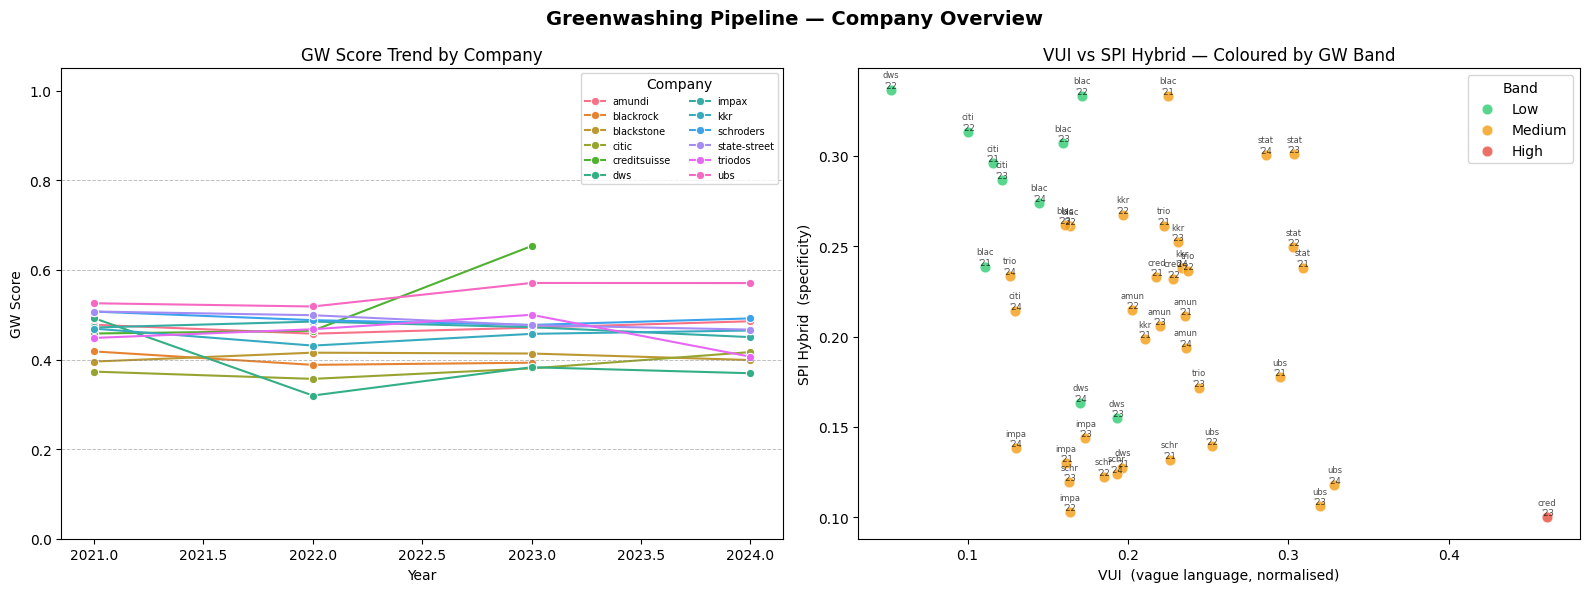

Saved: outputs/gw_overview.png


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

BAND_COLORS = {
    "very_low": "#27ae60", "low": "#2ecc71",
    "medium": "#f39c12", "high": "#e74c3c", "very_high": "#8e44ad",
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(
    "Greenwashing Pipeline — Company Overview",
    fontsize=14, fontweight="bold",
)

# --- Plot 1: GW trend lines per company ---
sns.lineplot(
    data=df, x="year", y="gw", hue="company",
    marker="o", linewidth=1.5, ax=axes[0],
)
for boundary in [0.20, 0.40, 0.60, 0.80]:
    axes[0].axhline(boundary, color="gray", linestyle="--", linewidth=0.7, alpha=0.5)
axes[0].set_title("GW Score Trend by Company")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("GW Score")
axes[0].set_ylim(0, 1.05)
axes[0].legend(fontsize=7, ncol=2, title="Company")

# --- Plot 2: VUI vs SPI scatter, coloured by GW band ---
for band, colour in BAND_COLORS.items():
    subset = df[df["band"] == band]
    if subset.empty:
        continue
    axes[1].scatter(
        subset["vui_norm"], subset["spi_hybrid"],
        c=colour, label=band.replace("_", " ").title(),
        alpha=0.8, s=60, edgecolors="white", linewidths=0.5,
    )
for _, row in df.iterrows():
    axes[1].annotate(
        f"{row['company'][:4]}\n'{str(row['year'])[2:]}",
        (row["vui_norm"], row["spi_hybrid"]),
        fontsize=6, ha="center", va="bottom", alpha=0.7,
    )
axes[1].set_title("VUI vs SPI Hybrid — Coloured by GW Band")
axes[1].set_xlabel("VUI  (vague language, normalised)")
axes[1].set_ylabel("SPI Hybrid  (specificity)")
axes[1].legend(title="Band")

plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/gw_overview.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: outputs/gw_overview.png")

In [4]:
import glob as _glob

# ---------------------------------------------------------------------------
# Regression check: compare batch DWS results against stored baselines.
# Stored baselines live in outputs/run_<year>.json (DWS-only runs).
# Expected behaviour:
#   2021 / 2022 — vui_norm, spi_hybrid, gw should match within TOL
#   2023        — gw will differ (CI now applied: ci_value=1.0 lowers GW)
#   2024        — should match (both runs used ci-values)
# ---------------------------------------------------------------------------
BASELINE_DIR = "outputs"
TOL = 0.001  # acceptable floating-point delta

baselines = {}
for path in sorted(_glob.glob(f"{BASELINE_DIR}/run_*.json")):
    with open(path) as f:
        b = json.load(f)
    baselines[b["year"]] = b

if not baselines:
    print("No baseline run_*.json files found in outputs/ — skipping validation.")
else:
    dws_batch = df[df["company"] == "dws"].set_index("year")

    print(f"{'Year':>4}  {'Metric':<12}  {'Baseline':>10}  {'Batch':>10}  Status")
    print("-" * 58)
    for year, b in sorted(baselines.items()):
        if year not in dws_batch.index:
            print(f"{year:>4}  (not in batch results — was this PDF skipped?)")
            continue
        row = dws_batch.loc[year]
        checks = {
            "vui_norm":   (round(b["vui"]["vui_norm"], 4), row["vui_norm"]),
            "spi_hybrid": (round(b["spi_hybrid"],       4), row["spi_hybrid"]),
            "gw":         (round(b["gw"]["gw"],         4), row["gw"]),
        }
        for metric, (base_val, batch_val) in checks.items():
            match = abs(base_val - batch_val) <= TOL
            flag  = "OK" if match else "DIFF  (expected if CI now applied)"
            print(
                f"{year:>4}  {metric:<12}  {base_val:>10.4f}  "
                f"{batch_val:>10.4f}  {flag}"
            )
        print()

Year  Metric          Baseline       Batch  Status
----------------------------------------------------------
2021  vui_norm          0.1965      0.1965  OK
2021  spi_hybrid        0.3701      0.1275  DIFF  (expected if CI now applied)
2021  gw                0.3861      0.4923  DIFF  (expected if CI now applied)

2022  vui_norm          0.0522      0.0522  OK
2022  spi_hybrid        0.6166      0.3366  DIFF  (expected if CI now applied)
2022  gw                0.1971      0.3196  DIFF  (expected if CI now applied)

2023  vui_norm          0.1933      0.1933  OK
2023  spi_hybrid        0.3765      0.1547  DIFF  (expected if CI now applied)
2023  gw                0.3052      0.3828  DIFF  (expected if CI now applied)

2024  vui_norm          0.1703      0.1703  OK
2024  spi_hybrid        0.1645      0.1634  DIFF  (expected if CI now applied)
2024  gw                0.3691      0.3694  OK



## Cell 5 — NLI-Enhanced Run & Comparison

Re-runs all PDFs with `--enable-nli` (uses `facebook/bart-large-mnli`), then shows a
side-by-side comparison of rule-only vs NLI-enhanced GW scores. Takes ~10-15 min.

In [5]:
# ---------------------------------------------------------------------------
# NLI-enhanced batch run  (requires torch + transformers)
# ---------------------------------------------------------------------------
nli_results = []
print("Running NLI-enhanced batch (this will take ~10-15 min)...\n")

for pdf_path in pdf_paths:
    stem = os.path.splitext(os.path.basename(pdf_path))[0]
    m = re.match(r"^(.+)-(\d{4})$", stem)
    if not m:
        continue
    company, year = m.group(1).lower(), int(m.group(2))

    outdir = os.path.join(REPO, "outputs", "batch_nli", company)
    os.makedirs(outdir, exist_ok=True)

    cmd = [
        sys.executable, "-m", "src.pilot",
        "--pdf", pdf_path,
        "--year", str(year),
        "--outdir", outdir,
        "--enable-nli",
    ]
    if company in CI_VALUES:
        cmd += ["--ci-values", CI_VALUES[company]]

    print(f"  {company:<15} {year} ...", end=" ", flush=True)
    try:
        proc = subprocess.run(
            cmd, capture_output=True, text=True, timeout=600, cwd=REPO,
        )
        if proc.returncode != 0:
            print("ERROR")
            nli_results.append({"company": company, "year": year,
                                "error": proc.stderr.strip()[-300:]})
        else:
            data = json.loads(proc.stdout)
            print(f"GW={data['gw']:.3f}  ({data['band']})")
            nli_results.append({
                "company":    company,
                "year":       year,
                "vui_norm":   data["vui_norm"],
                "spi_hybrid": data["spi_hybrid"],
                "gw":         data["gw"],
                "band":       data["band"],
                "ci_value":   data.get("ci_value"),
            })
    except subprocess.TimeoutExpired:
        print("TIMEOUT")
        nli_results.append({"company": company, "year": year, "error": "TIMEOUT"})
    except Exception as exc:
        print(f"EXCEPTION: {exc}")
        nli_results.append({"company": company, "year": year, "error": str(exc)})

ok_nli  = sum(1 for r in nli_results if "gw"    in r)
err_nli = sum(1 for r in nli_results if "error" in r)
print(f"\nNLI batch finished: {ok_nli} succeeded, {err_nli} failed.")

Running NLI-enhanced batch (this will take ~10-15 min)...

  kkr             2021 ... GW=0.451  (medium)
  kkr             2022 ... GW=0.414  (medium)
  kkr             2023 ... GW=0.436  (medium)
  kkr             2024 ... GW=0.396  (low)
  ubs             2021 ... GW=0.426  (medium)
  ubs             2022 ... GW=0.404  (medium)
  ubs             2023 ... GW=0.451  (medium)
  ubs             2024 ... GW=0.454  (medium)
  amundi          2021 ... GW=0.413  (medium)
  amundi          2022 ... GW=0.394  (low)
  amundi          2023 ... GW=0.399  (low)
  amundi          2024 ... GW=0.398  (low)
  blackrock       2021 ... GW=0.451  (medium)
  blackrock       2022 ... GW=0.376  (low)
  blackrock       2023 ... GW=0.367  (low)
  blackstone      2021 ... GW=0.296  (low)
  blackstone      2022 ... GW=0.340  (low)
  blackstone      2023 ... GW=0.324  (low)
  blackstone      2024 ... GW=0.329  (low)
  citic           2021 ... GW=0.272  (low)
  citic           2022 ... GW=0.254  (low)
  citic    

In [6]:
# ---------------------------------------------------------------------------
# Side-by-side comparison: Rule-Only vs NLI
# ---------------------------------------------------------------------------
nli_ok = [r for r in nli_results if "gw" in r]
df_nli = pd.DataFrame(nli_ok).sort_values(["company", "year"]).reset_index(drop=True)

comparison = df[["company", "year", "gw", "band", "spi_hybrid"]].merge(
    df_nli[["company", "year", "gw", "band", "spi_hybrid"]],
    on=["company", "year"],
    suffixes=("_rule", "_nli"),
)
comparison["gw_delta"] = comparison["gw_nli"] - comparison["gw_rule"]

print(f"Comparison: {len(comparison)} rows matched.\n")
print(f"Mean GW delta (NLI − Rule): {comparison['gw_delta'].mean():+.4f}")
print(f"NLI higher in {(comparison['gw_delta'] > 0).sum()}/{len(comparison)} cases")
print()

comparison[["company", "year", "gw_rule", "gw_nli", "gw_delta",
            "band_rule", "band_nli", "spi_hybrid_rule", "spi_hybrid_nli"]]

Comparison: 46 rows matched.

Mean GW delta (NLI − Rule): -0.0857
NLI higher in 1/46 cases



,company,year,gw_rule,gw_nli,gw_delta,band_rule,band_nli,spi_hybrid_rule,spi_hybrid_nli
0,amundi,2021,0.4776,0.4127,-0.0649,medium,medium,0.2113,0.3597
1,amundi,2022,0.4577,0.3937,-0.0640,medium,low,0.2146,0.3607
2,amundi,2023,0.4712,0.3985,-0.0727,medium,low,0.2057,0.3719
3,amundi,2024,0.4854,0.3981,-0.0873,medium,low,0.1938,0.3935
4,blackrock,2021,0.4181,0.4514,0.0333,medium,medium,0.3333,0.2571
5,blackrock,2022,0.3881,0.3764,-0.0117,low,low,0.3333,0.3600
6,blackrock,2023,0.3929,0.3671,-0.0258,low,low,0.3071,0.3661
7,blackstone,2021,0.3955,0.2965,-0.0990,low,low,0.2386,0.4649
8,blackstone,2022,0.4153,0.3398,-0.0755,medium,low,0.2612,0.4336
9,blackstone,2023,0.4134,0.3243,-0.0891,medium,low,0.2615,0.4652


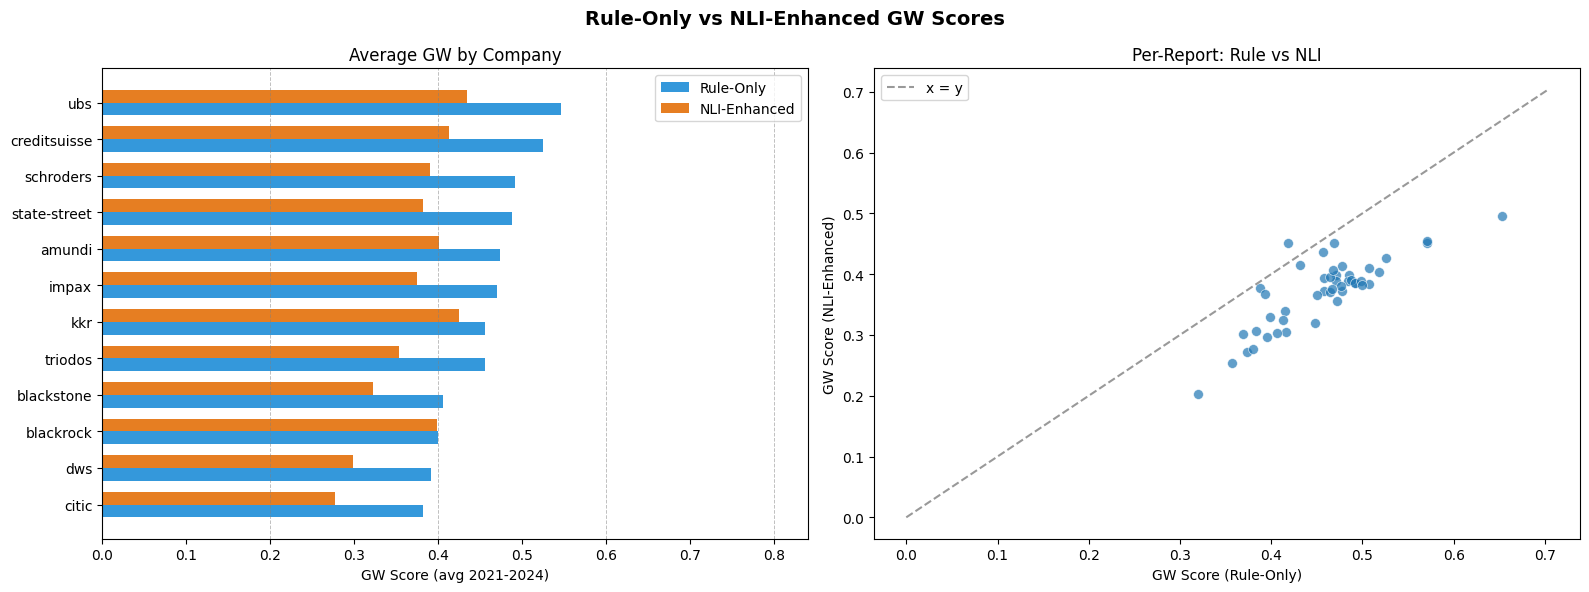

Saved: outputs/gw_rule_vs_nli.png


In [7]:
# ---------------------------------------------------------------------------
# Plot: Rule-Only vs NLI GW scores
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Rule-Only vs NLI-Enhanced GW Scores", fontsize=14, fontweight="bold")

# --- Plot 1: paired bar chart per company (averaged across years) ---
avg = comparison.groupby("company")[["gw_rule", "gw_nli"]].mean().sort_values("gw_rule")
x = range(len(avg))
w = 0.35
axes[0].barh([i - w/2 for i in x], avg["gw_rule"], w, label="Rule-Only", color="#3498db")
axes[0].barh([i + w/2 for i in x], avg["gw_nli"],  w, label="NLI-Enhanced", color="#e67e22")
axes[0].set_yticks(list(x))
axes[0].set_yticklabels(avg.index)
axes[0].set_xlabel("GW Score (avg 2021-2024)")
axes[0].set_title("Average GW by Company")
axes[0].legend()
for boundary in [0.20, 0.40, 0.60, 0.80]:
    axes[0].axvline(boundary, color="gray", linestyle="--", linewidth=0.7, alpha=0.5)

# --- Plot 2: scatter — rule vs NLI per observation ---
axes[1].scatter(comparison["gw_rule"], comparison["gw_nli"],
                alpha=0.7, s=50, edgecolors="white", linewidths=0.5)
lims = [0, max(comparison["gw_rule"].max(), comparison["gw_nli"].max()) + 0.05]
axes[1].plot(lims, lims, "k--", alpha=0.4, label="x = y")
axes[1].set_xlabel("GW Score (Rule-Only)")
axes[1].set_ylabel("GW Score (NLI-Enhanced)")
axes[1].set_title("Per-Report: Rule vs NLI")
axes[1].legend()

plt.tight_layout()
plt.savefig("outputs/gw_rule_vs_nli.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: outputs/gw_rule_vs_nli.png")